## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import folium

import statsmodels.api as sm
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression, Lasso

import matplotlib.pyplot as plt

## Preprocessing Datasets

In [2]:
# Reading in the datasets
weather = pd.read_csv("weather.csv")
crime = pd.read_csv("bikes_cm.csv", dtype={0: str, 1: str, 3: str, 4: str})
unemp = pd.read_csv("unemployment.csv", skiprows=7, dtype={1:float})
unemp.columns = ['date', 'pct_unemp']

# Subsetting to bicycle theft occuring in West Midlands only
bikes_intermediate = crime[
    (crime['crime'] == "Bicycle theft") &
    (crime['Latitude'] >= 52.25) &
    (crime['Latitude'] <= 52.7) &
    (crime['Longitude'] >= -2.45) &
    (crime['Longitude'] <= -1.16)]
# Grabbing my visualization data real quick
bikes_for_map = bikes_intermediate.copy()
bikes_for_map['date'] = pd.to_datetime(bikes_for_map['date'], format = "%Y-%m-%d")
bikes_for_map = bikes_for_map[(bikes_for_map['date'] > '2013-04') & (bikes_for_map['date'] < '2026-01')]

bikes = bikes_intermediate.groupby('date')['crime'].count()
# Merging theft and weather datasets
join_one = pd.merge(bikes, weather, on='date', how='inner')
# Formatting date to NumPy datetime object type
join_one['date'] = pd.to_datetime(join_one['date'], format = "%Y-%m-%d")
# Cutting to end of 2025
join_one = join_one[join_one['date'] < '2026-01']
# Formatting Unemployment Data
unemp['date'] = pd.to_datetime(unemp['date'], format='%Y %b', errors='coerce')
unemp = unemp[unemp['date'] > '2013-04']
# Final merge
df = pd.merge(join_one, unemp, on='date', how='inner')

In [3]:
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')

# time trend control
df['time'] = np.arange(len(df))

In [4]:
# weather lags (will include in some models and not in others, seeing what works)
df['rain_lag1'] = df['rain'].shift(1)
df['sun_lag1'] = df['sun'].shift(1)   
df['tmax_lag1'] = df['tmax'].shift(1)
df['af_lag1'] = df['af'].shift(1)

# unemployment lags (again, some models will utilize)
df['unemp_lag1'] = df['pct_unemp'].shift(1)
df = df.dropna()

In [5]:
# Seeing where we should split for train and test data
# (in an effort to control for time trends, this is not random, but aligned with time.)
df.date.quantile(0.8)

Timestamp('2023-06-01 00:00:00')

In [6]:
train = df[df.date < '2023-06-01']
test  = df[df.date >= '2023-06-01']

In [7]:
# Getting boolean month dummies (and turning them into integers for computing)
train = pd.get_dummies(train, columns=['month'], drop_first=True)
test  = pd.get_dummies(test, columns=['month'], drop_first=True)

train, test = train.align(test, join='left', axis=1, fill_value=0)
for col in train.columns:
    if train[col].dtype == 'bool':
        train[col] = train[col].astype(int)
        test[col]  = test[col].astype(int)

In [8]:
# OUR MAIN FEATURE SETS
month_dummies = [c for c in train.columns if c.startswith('month_')]

features_nolag = ['tmax', 'rain', 'sun', 'af', 'pct_unemp', 'time'] + \
                 [c for c in train.columns if c.startswith('month_')]

features_lag = ['tmax_lag1', 'rain_lag1', 'sun_lag1', 'af_lag1',
                'unemp_lag1', 'time'] + \
               [c for c in train.columns if c.startswith('month_')]

## Initial Visualizations

In [9]:
df.head()

,date,crime,year,month,tmax,tmin,af,rain,sun,pct_unemp,time,rain_lag1,sun_lag1,tmax_lag1,af_lag1,unemp_lag1
1,2013-06-01,301,2013,6,18.3,8.4,0.0,28.4,163.0,9.7,1,84.0,163.7,14.7,0.0,9.8
2,2013-07-01,352,2013,7,24.1,12.1,0.0,59.2,257.4,9.3,2,28.4,163.0,18.3,0.0,9.7
3,2013-08-01,354,2013,8,20.8,11.5,0.0,66.2,125.5,9.3,3,59.2,257.4,24.1,0.0,9.3
4,2013-09-01,342,2013,9,17.9,9.3,0.0,33.4,106.4,8.9,4,66.2,125.5,20.8,0.0,9.3
5,2013-10-01,313,2013,10,15.6,9.0,0.0,96.6,75.3,8.2,5,33.4,106.4,17.9,0.0,8.9


In [10]:
# Creating map for visualizing geographical spread of bicycle theft
m = folium.Map(location=[52.48, -1.9], zoom_start=9)

for lat, lon in zip(bikes_for_map["Latitude"], bikes_for_map["Longitude"]):
    folium.CircleMarker(
        location=[lat, lon],
        radius=2,
        color="blue",
        fill=True,
        fill_opacity=0.2,
        stroke=False
    ).add_to(m)
    
# m.save("map.html")

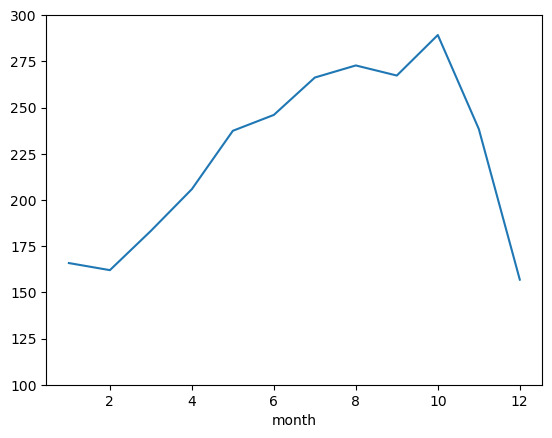

In [11]:
# Which months have the most bicycle theft?
fig = df.groupby('month')['crime'].mean().plot()
fig.set_ylim(100, 300)
# plt.savefig('months.png')
plt.show()

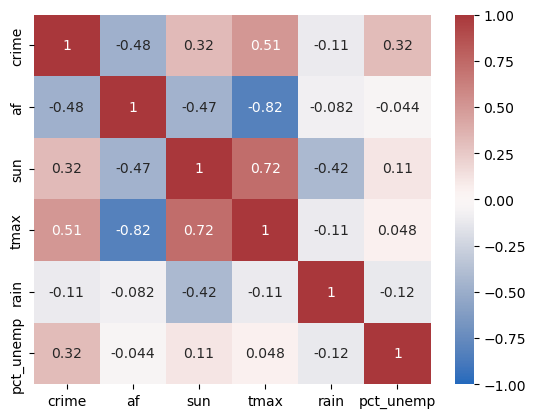

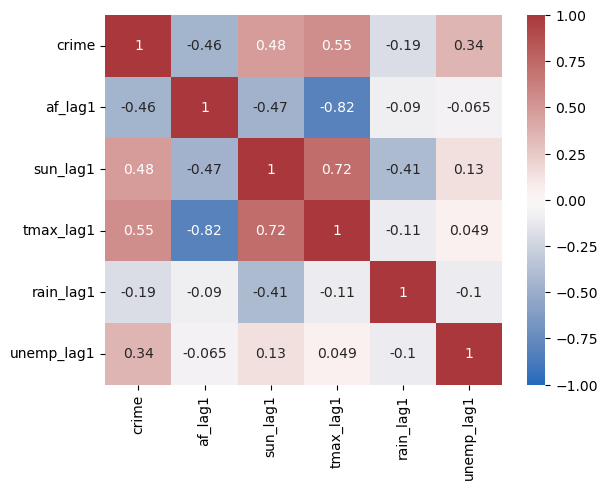

In [12]:
# Checking correlation between variables, no lag, then lag.
sns.heatmap(df[['crime', 'af', 'sun', 'tmax', 'rain', 'pct_unemp']].corr(),
            vmin = -1, vmax = 1, annot=True, cmap='vlag')
plt.show()

sns.heatmap(df[['crime', 'af_lag1', 'sun_lag1', 'tmax_lag1', 'rain_lag1', 'unemp_lag1']].corr(),
            vmin = -1, vmax = 1, annot=True, cmap='vlag')
plt.show()

# plt.savefig('heatmap.png')
# plt.savefig('lagged_heatmap.png')

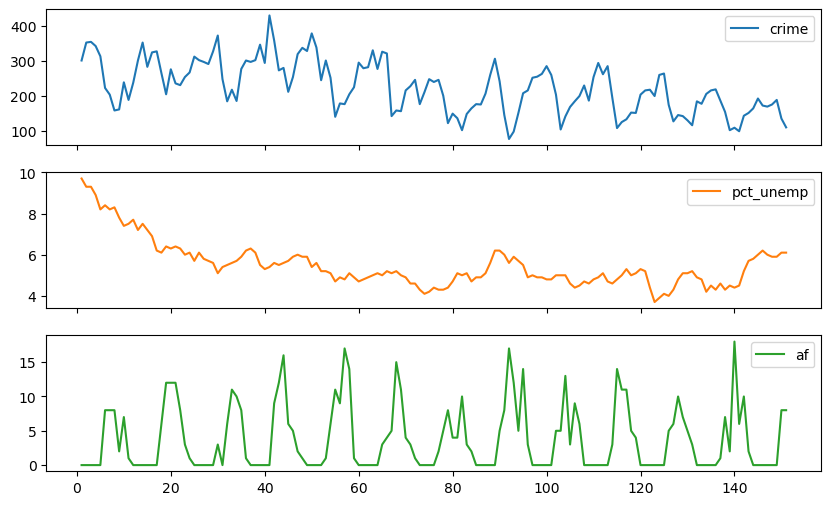

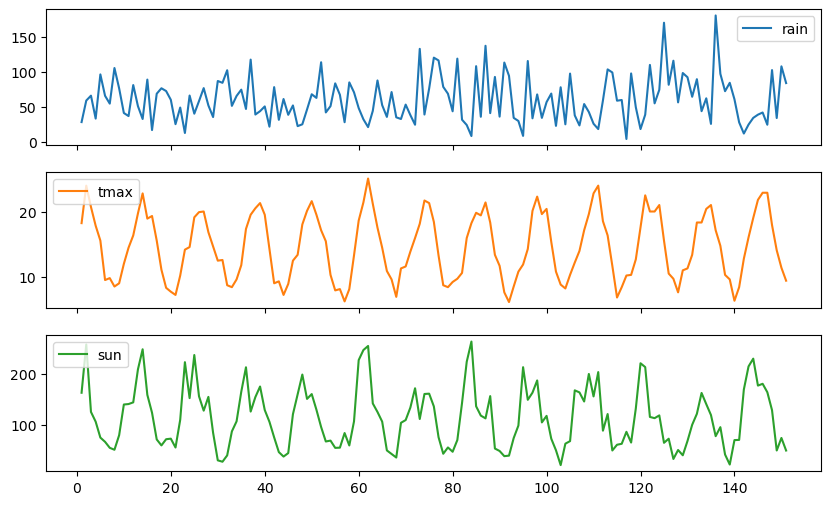

In [13]:
# Looking at trends over time:

df[['crime', 'pct_unemp', 'af']].plot(subplots=True, figsize=(10,6))
# plt.savefig('timeseries1.png')
plt.show()

df[['rain', 'tmax', 'sun']].plot(subplots=True, figsize=(10,6))
# plt.savefig('timeseries2.png')
plt.show()

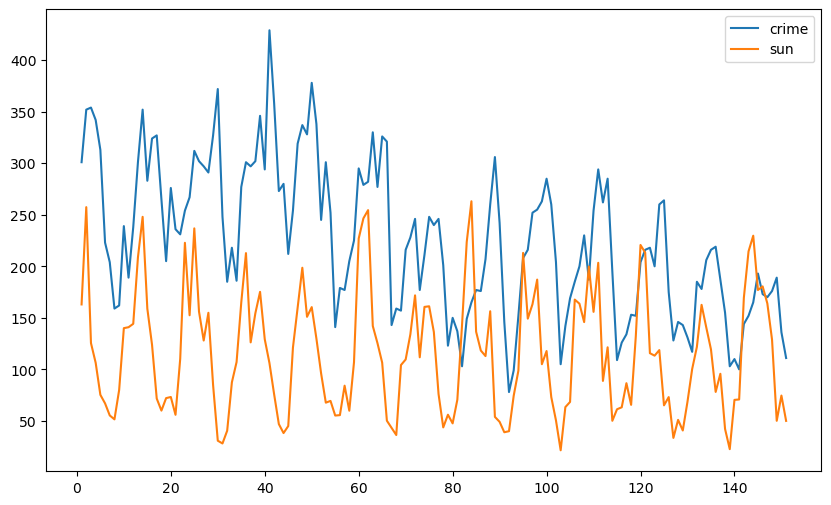

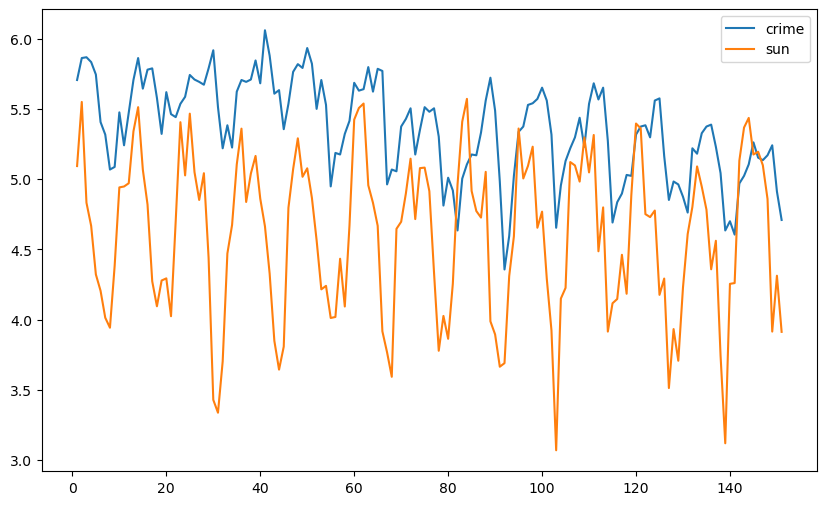

In [14]:
df[['crime', 'sun']].plot(figsize=(10,6))
# plt.savefig('timeseries3.png')
plt.show()

np.log(df[['crime', 'sun']]).plot(figsize=(10,6))
# plt.savefig('timeseries3_log.png')
plt.show()

## Developing Initial Models

In [15]:
# Making a function that runs each of our models makes comparison of feature sets easier.
# OLS:
def run_ols(train, test, feature_set):
    X_train = sm.add_constant(train[feature_set])
    y_train = train['crime']
    model = sm.OLS(y_train, X_train).fit()
    X_test = sm.add_constant(test[feature_set])
    y_test = test['crime']
    preds = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    return model, rmse
# Random Forest:
def run_rf(train, test, features):
    rf = RandomForestRegressor(n_estimators=500, max_depth=3, random_state=42)
    rf.fit(train[features], train['crime'])
    pred_train = rf.predict(train[features])
    pred_test  = rf.predict(test[features])
    # RMSEs
    rmse_train = np.sqrt(mean_squared_error(train['crime'], pred_train))
    rmse_test  = np.sqrt(mean_squared_error(test['crime'], pred_test))
    return rf, rmse_train, rmse_test


In [16]:
# Running OLS
ols_nolag, rmse_ols_nolag = run_ols(train, test, features_nolag)
ols_lag, rmse_ols_lag     = run_ols(train, test, features_lag)

# Running Random Forest
rf_nolag, rmse_rf_train_nolag, rmse_rf_test_nolag = run_rf(train, test, features_nolag)
rf_lag,   rmse_rf_train_lag,   rmse_rf_test_lag   = run_rf(train, test, features_lag)

In [17]:
ols_lag.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  crime   R-squared:                       0.718
Model:                            OLS   Adj. R-squared:                  0.671
Method:                 Least Squares   F-statistic:                     15.28
Date:                Fri, 17 Apr 2026   Prob (F-statistic):           6.71e-21
Time:                        16:30:52   Log-Likelihood:                -606.67
No. Observations:                 120   AIC:                             1249.
Df Residuals:                     102   BIC:                             1300.
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        276.3078     62.206      4.442      0.000     152.922     399.694
tmax_lag1      3.4158      4.296      0.795      0.428      -5.106      11.937
rain_lag1     -0.3437      0.153     -2.250      0.027      -0.647      -0.041
sun_lag1      -0.1787      0.165     -1.085      0.280      -0.505       0.148
af_lag1        1.7325      1.931      0.897      0.372      -2.097       5.562
unemp_lag1    -7.7217      4.679     -1.650      0.102     -17.003       1.559
time          -1.1550      0.165     -6.995      0.000      -1.482      -0.827
month_2       -4.6789     18.903     -0.248      0.805     -42.172      32.814
month_3       18.3622     18.934      0.970      0.334     -19.193      55.917
month_4       50.2444     20.349      2.469      0.015       9.882      90.607
month_5       80.3740     25.437      3.160      0.002      29.919     130.829
month_6       87.7199     31.115      2.819      0.006      26.003     149.437
month_7      105.6824     38.044      2.778      0.007      30.223     181.142
month_8      103.2989     44.914      2.300      0.023      14.212     192.386
month_9       93.8534     42.018      2.234      0.028      10.511     177.196
month_10     128.6413     34.578      3.720      0.000      60.057     197.226
month_11      86.4139     25.881      3.339      0.001      35.079     137.749
month_12      -7.3372     19.233     -0.381      0.704     -45.485      30.811
==============================================================================
Omnibus:                        0.596   Durbin-Watson:                   1.044
Prob(Omnibus):                  0.742   Jarque-Bera (JB):                0.701
Skew:                          -0.009   Prob(JB):                        0.704
Kurtosis:                       2.626   Cond. No.                     3.76e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.76e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [18]:
# Now we can compare models's RMSE values
print(f"RMSE OLS (no lag): {rmse_ols_nolag:.2f}")
print(f"RMSE OLS (lag): {rmse_ols_lag:.2f}")

print("=== RANDOM FOREST PERFORMANCE ===")

print("\nNo Lag:")
print(f"Train RMSE: {rmse_rf_train_nolag:.2f}")
print(f"Test  RMSE: {rmse_rf_test_nolag:.2f}")

print("\nLag:")
print(f"Train RMSE: {rmse_rf_train_lag:.2f}")
print(f"Test  RMSE: {rmse_rf_test_lag:.2f}")

RMSE OLS (no lag): 28.41
RMSE OLS (lag): 24.08
=== RANDOM FOREST PERFORMANCE ===

No Lag:
Train RMSE: 33.22
Test  RMSE: 47.08

Lag:
Train RMSE: 30.23
Test  RMSE: 47.35


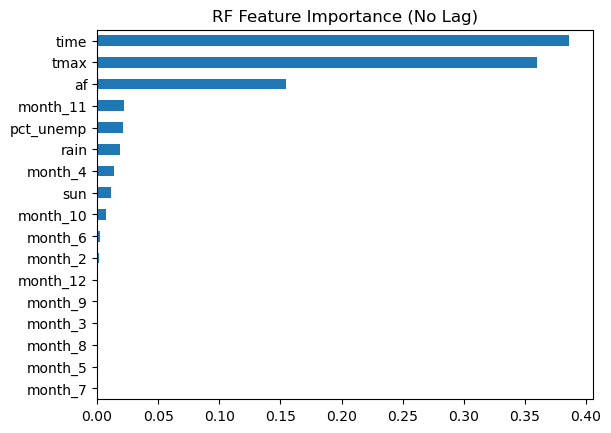

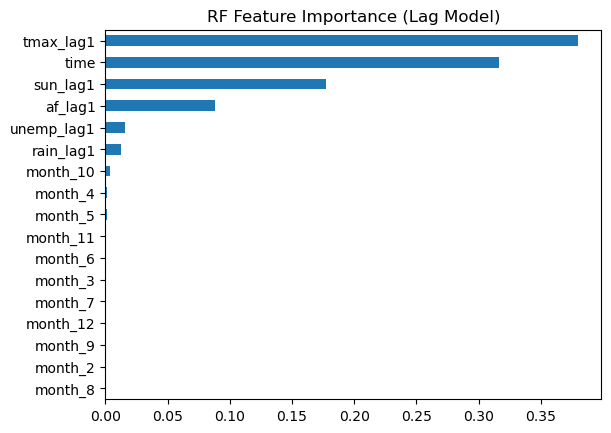

In [19]:
# Checking Feature Importance for Random Forest
importances_nolag = pd.Series(rf_nolag.feature_importances_, index=features_nolag)
importances_nolag.sort_values().plot(kind='barh')
plt.title("RF Feature Importance (No Lag)")
plt.show()

importances = pd.Series(rf_lag.feature_importances_, index=features_lag)
importances.sort_values().plot(kind='barh')
plt.title("RF Feature Importance (Lag Model)")
plt.show()

## Principal Component Analysis Experimentetion

In [20]:
# Setting up PCA, no lag
weather = ['tmax', 'rain', 'sun', 'af']

scaler = StandardScaler()
X_scaled_train = scaler.fit_transform(train[weather])

pca = PCA(n_components=2)
pcs_train = pca.fit_transform(X_scaled_train)

train['PC1'] = pcs_train[:, 0]
train['PC2'] = pcs_train[:, 1]

X_scaled_whole = scaler.fit_transform(df[weather])

pca_whole = PCA(n_components=2)
pcs_whole = pca_whole.fit_transform(X_scaled_whole)
df['PC1_whole'] = pcs_whole[:,0]
df['PC2_whole'] = pcs_whole[:,1]

# Applying PCA to test data (no lag)
X_scaled_test = scaler.transform(test[weather])
pcs_test = pca.transform(X_scaled_test)

test['PC1'] = pcs_test[:, 0]
test['PC2'] = pcs_test[:, 1]

In [21]:
# Setting up PCA, with lag
weather_lag1 = ['tmax_lag1', 'rain_lag1', 'sun_lag1', 'af_lag1']

scaler = StandardScaler()
X_scaled_train_lag = scaler.fit_transform(train[weather_lag1])

pca_lag = PCA(n_components=2)
pcs_train_lag = pca_lag.fit_transform(X_scaled_train_lag)

train['PC3'] = pcs_train_lag[:, 0]
train['PC4'] = pcs_train_lag[:, 1]


X_scaled_whole_lag = scaler.fit_transform(df[weather_lag1])
pca_whole_lag = PCA(n_components=2)
pcs_whole_lag = pca_whole_lag.fit_transform(X_scaled_whole_lag)
df['PC3_whole'] = pcs_whole_lag[:,0]
df['PC4_whole'] = pcs_whole_lag[:,1]

# Applying PCA (with lag)
X_scaled_test_lag = scaler.transform(test[weather_lag1])
pcs_test_lag = pca_lag.transform(X_scaled_test_lag)

test['PC3'] = pcs_test_lag[:, 0]
test['PC4'] = pcs_test_lag[:, 1]

In [22]:
# Extracting PCA features (w and without lag)
features_pca_nolag = ['PC1', 'PC2', 'pct_unemp', 'time'] + \
               [c for c in train.columns if c.startswith('month_')]

features_pca_lag = ['PC3', 'PC4', 'pct_unemp', 'time'] + \
               [c for c in train.columns if c.startswith('month_')]

In [23]:
# Comparing components across use of PCA in whole vs train and test datasets, 
# with and without lag (PC1 and PC2 without lag, PC3 and PC4 with lag).

PC_tt_nolag = pd.DataFrame(
    pca.components_,
    columns=weather,
    index=['PC1', 'PC2'])

PC_whole_nolag = pd.DataFrame(
    pca_whole.components_,
    columns=weather,
    index=['PC1_whole', 'PC2_whole'])

PC_tt_lag = pd.DataFrame(
    pca_lag.components_,
    columns=weather_lag1,
    index=['PC3', 'PC4'])

PC_whole_lag = pd.DataFrame(
    pca_whole_lag.components_,
    columns=weather_lag1,
    index=['PC3_whole', 'PC4_whole'])


print(PC_tt_nolag)
print('----------------------------------------------')
print(PC_whole_nolag)
print('----------------------------------------------')
print(PC_tt_lag)
print('----------------------------------------------')
print(PC_whole_lag)

         tmax      rain       sun        af
PC1  0.615975 -0.163776  0.549628 -0.540056
PC2  0.143467  0.866748 -0.281616 -0.385820
----------------------------------------------
               tmax      rain       sun        af
PC1_whole  0.614577 -0.182339  0.550908 -0.534367
PC2_whole  0.160932  0.850055 -0.292983 -0.407024
----------------------------------------------
     tmax_lag1  rain_lag1  sun_lag1   af_lag1
PC3   0.618515  -0.147977  0.548700 -0.542651
PC4   0.126950   0.871942 -0.282772 -0.378999
----------------------------------------------
           tmax_lag1  rain_lag1  sun_lag1   af_lag1
PC3_whole   0.615684  -0.174973  0.550377 -0.536100
PC4_whole   0.154408   0.852162 -0.295011 -0.403667


In [24]:
# Running models with PCA (w and without lag)-- NOTE lack of month control.
X_OLS_PC12 = sm.add_constant(df[['PC1_whole', 'PC2_whole', 'pct_unemp', 'time']])
X_OLS_PC34 = sm.add_constant(df[['PC3_whole', 'PC4_whole', 'pct_unemp', 'time']])
ols_pca_whole_lag = sm.OLS(df['crime'], X_OLS_PC12).fit()
ols_pca_whole_nolag = sm.OLS(df['crime'], X_OLS_PC34).fit()

# Train and test data with month controls
ols_pca_nolag, rmse_ols_pca_nolag = run_ols(train, test, features_pca_nolag)
ols_pca_lag, rmse_ols_pca_lag = run_ols(train, test, features_pca_lag)

rf_pca_nolag, rmse_rf_train_pca_nolag, rmse_rf_test_pca_nolag   = run_rf(train, test, features_pca_nolag)
rf_pca_lag, rmse_rf_train_pca_lag, rmse_rf_test_pca_lag = run_rf(train, test, features_pca_lag)

In [25]:
print("=== OLS WHOLE DATA ===")
print(ols_pca_whole_lag.summary())
print(ols_pca_whole_nolag.summary())

print("\n=== OLS TRAIN/TEST DATA ===")

print(f"RMSE OLS (no lag, PCA Features): {rmse_ols_pca_nolag:.2f}")
print(f"RMSE OLS (lag, PCA Features): {rmse_ols_pca_lag:.2f}")
print("\n=== RANDOM FOREST ===")

print("\nNo Lag:")
print(f"Train RMSE: {rmse_rf_train_pca_nolag:.2f}")
print(f"Test  RMSE: {rmse_rf_test_pca_nolag:.2f}")

print("\nLag:")
print(f"Train RMSE: {rmse_rf_train_pca_lag:.2f}")
print(f"Test  RMSE: {rmse_rf_test_pca_lag:.2f}")

=== OLS WHOLE DATA ===
                            OLS Regression Results                            
Dep. Variable:                  crime   R-squared:                       0.599
Model:                            OLS   Adj. R-squared:                  0.588
Method:                 Least Squares   F-statistic:                     54.54
Date:                Fri, 17 Apr 2026   Prob (F-statistic):           4.73e-28
Time:                        16:30:53   Log-Likelihood:                -791.66
No. Observations:                 151   AIC:                             1593.
Df Residuals:                     146   BIC:                             1608.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        355.2589     30.

In [26]:
ols_pca_lag.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  crime   R-squared:                       0.711
Model:                            OLS   Adj. R-squared:                  0.669
Method:                 Least Squares   F-statistic:                     17.04
Date:                Fri, 17 Apr 2026   Prob (F-statistic):           1.32e-21
Time:                        16:30:53   Log-Likelihood:                -608.19
No. Observations:                 120   AIC:                             1248.
Df Residuals:                     104   BIC:                             1293.
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        276.4086     40.125      6.889      0.000     196.839     355.979
PC3           -1.7353      7.407     -0.234      0.815     -16.424      12.953
PC4           -9.5999      4.185     -2.294      0.024     -17.900      -1.300
pct_unemp     -6.5789      4.863     -1.353      0.179     -16.223       3.065
time          -1.0830      0.161     -6.745      0.000      -1.401      -0.765
month_2       -7.0832     18.867     -0.375      0.708     -44.497      30.330
month_3       13.6093     18.777      0.725      0.470     -23.625      50.844
month_4       44.0650     19.745      2.232      0.028       4.909      83.221
month_5       72.4981     24.476      2.962      0.004      23.961     121.036
month_6       83.7309     29.219      2.866      0.005      25.789     141.673
month_7      114.5406     31.787      3.603      0.000      51.506     177.575
month_8      120.6019     34.300      3.516      0.001      52.584     188.620
month_9      113.5414     31.245      3.634      0.000      51.582     175.501
month_10     142.7424     28.441      5.019      0.000      86.342     199.143
month_11      95.9168     23.984      3.999      0.000      48.355     143.479
month_12      -4.1746     19.080     -0.219      0.827     -42.011      33.662
==============================================================================
Omnibus:                        0.735   Durbin-Watson:                   1.012
Prob(Omnibus):                  0.692   Jarque-Bera (JB):                0.810
Skew:                           0.053   Prob(JB):                        0.667
Kurtosis:                       2.612   Cond. No.                     1.40e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.4e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## Lasso Experimentation

In [27]:
# Maybe let's just try Lasso to see which variables are actually worth 
# their weight before doing Double Machine Learning.
# gotta use scaled ones:

def run_lasso(train, test, feature_set, alpha=1.0):
    scaler = StandardScaler()
    X_train = train[feature_set]
    y_train = train['crime']
    X_test = test[feature_set]
    y_test = test['crime']
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    model = Lasso(alpha=alpha, max_iter=10000)
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    return model, rmse

In [28]:
lasso_nolag, rmse_lasso_nolag = run_lasso(train, test, features_nolag)
lasso_lag, rmse_lasso_lag = run_lasso(train, test, features_lag)
print(f"RMSE Lasso (no lag): {rmse_lasso_nolag:.2f}")
print(f"RMSE Lasso (lag): {rmse_lasso_lag:.2f}")

RMSE Lasso (no lag): 26.30
RMSE Lasso (lag): 22.02


In [29]:
lasso_lag_coef = pd.Series(lasso_lag.coef_, index=train[features_lag].columns)
print(lasso_lag_coef)
print("------------")
lasso_nolag_coef = pd.Series(lasso_lag.coef_, index=train[features_nolag].columns)
print(lasso_nolag_coef)

tmax_lag1     35.158297
rain_lag1     -7.459265
sun_lag1       0.000000
af_lag1        0.000000
unemp_lag1    -4.668574
time         -35.351067
month_2       -2.757813
month_3       -0.000000
month_4        3.330052
month_5        5.150005
month_6        1.100946
month_7        2.823659
month_8        0.000000
month_9        0.000000
month_10      12.918822
month_11       7.029930
month_12      -8.934383
dtype: float64
------------
tmax         35.158297
rain         -7.459265
sun           0.000000
af            0.000000
pct_unemp    -4.668574
time        -35.351067
month_2      -2.757813
month_3      -0.000000
month_4       3.330052
month_5       5.150005
month_6       1.100946
month_7       2.823659
month_8       0.000000
month_9       0.000000
month_10     12.918822
month_11      7.029930
month_12     -8.934383
dtype: float64


## Double Machine Learning

In [30]:
# Making a DML function
def run_dml(Y, D, X, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    Y_res = np.zeros(len(Y))
    D_res = np.zeros(len(D))
    for train_idx, test_idx in kf.split(X):
        X_train, X_test = X[train_idx], X[test_idx]
        Y_train, Y_test = Y[train_idx], Y[test_idx]
        D_train, D_test = D[train_idx], D[test_idx]
        g = RandomForestRegressor(n_estimators=500, max_depth=3, random_state=42)
        m = RandomForestRegressor(n_estimators=500, max_depth=3, random_state=42)
        g.fit(X_train, Y_train)
        Y_res[test_idx] = Y_test - g.predict(X_test)
        m.fit(X_train, D_train)
        D_res[test_idx] = D_test - m.predict(X_test)
    X_DML = sm.add_constant(D_res)
    return sm.OLS(Y_res, X_DML).fit()

In [31]:
# Double Machine Learning
f_1 = ['tmax', 'rain', 'sun', 'af', 'time'] + month_dummies
f_2 = ['tmax_lag1', 'rain_lag1', 'sun_lag1', 'af_lag1', 'time'] + month_dummies

Y = train['crime'].values
D = train['pct_unemp'].values
X = train[f_1].values

# Double Machine Learning with lags:
D_lag1 = train['unemp_lag1'].values
X_lag1 = train[f_2].values

# Double Machine Learning with PCA:
D_pca = train['pct_unemp'].values
X_pca = train[['PC1', 'PC2', 'time'] + month_dummies].values

D_pca_lag = train['unemp_lag1'].values
X_pca_lag = train[['PC3', 'PC4', 'time'] + month_dummies].values

# Double Machine Learning weather control for time/monthly effects
D_weather = train['PC1'].values
X_weather = train[['time', 'pct_unemp'] + month_dummies].values

D_weather_lag = train['PC3'].values
X_weather_lag = train[['time', 'unemp_lag1'] + month_dummies].values

# DML with tmax, control for time/monthly, other weather effects
D_tmax = train['tmax'].values
X_tmax = train[['time', 'rain', 'af', 'sun', 'pct_unemp'] + month_dummies].values

D_tmax_lag = train['tmax_lag1'].values
X_tmax_lag = train[['time', 'rain_lag1', 'af_lag1', 'sun_lag1', 'unemp_lag1'] + month_dummies].values

In [32]:
dml = run_dml(Y, D, X)
dml_lag = run_dml(Y, D_lag1, X_lag1)
dml_pca = run_dml(Y, D_pca, X_pca)
dml_pca_lag = run_dml(Y, D_pca_lag, X_pca_lag)
dml_weather = run_dml(Y, D_weather, X_weather)
dml_weather_lag = run_dml(Y, D_weather_lag, X_weather_lag)
dml_tmax = run_dml(Y, D_tmax, X_tmax)
dml_tmax_lag = run_dml(Y, D_tmax_lag, X_tmax_lag)

In [33]:
dml.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.008
Method:                 Least Squares   F-statistic:                    0.1102
Date:                Fri, 17 Apr 2026   Prob (F-statistic):              0.741
Time:                        16:31:09   Log-Likelihood:                -631.31
No. Observations:                 120   AIC:                             1267.
Df Residuals:                     118   BIC:                             1272.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.7610      4.295     -0.410      0.683     -10.266       6.744
x1             3.4745     10.469      0.332      0.741     -17.257      24.206
==============================================================================
Omnibus:                       11.267   Durbin-Watson:                   1.325
Prob(Omnibus):                  0.004   Jarque-Bera (JB):               11.938
Skew:                           0.644   Prob(JB):                      0.00256
Kurtosis:                       3.853   Cond. No.                         2.44
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [34]:
dml_lag.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.012
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     1.430
Date:                Fri, 17 Apr 2026   Prob (F-statistic):              0.234
Time:                        16:31:09   Log-Likelihood:                -616.78
No. Observations:                 120   AIC:                             1238.
Df Residuals:                     118   BIC:                             1243.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.4961      3.804     -0.393      0.695      -9.029       6.036
x1            12.0756     10.098      1.196      0.234      -7.922      32.073
==============================================================================
Omnibus:                        0.669   Durbin-Watson:                   1.491
Prob(Omnibus):                  0.716   Jarque-Bera (JB):                0.667
Skew:                           0.174   Prob(JB):                        0.716
Kurtosis:                       2.892   Cond. No.                         2.66
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [35]:
dml_pca.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.008
Method:                 Least Squares   F-statistic:                   0.02752
Date:                Fri, 17 Apr 2026   Prob (F-statistic):              0.869
Time:                        16:31:09   Log-Likelihood:                -635.49
No. Observations:                 120   AIC:                             1275.
Df Residuals:                     118   BIC:                             1281.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.3981      4.448     -0.539      0.591     -11.206       6.410
x1            -1.8858     11.368     -0.166      0.869     -24.398      20.626
==============================================================================
Omnibus:                        5.116   Durbin-Watson:                   1.215
Prob(Omnibus):                  0.077   Jarque-Bera (JB):                4.552
Skew:                           0.447   Prob(JB):                        0.103
Kurtosis:                       3.335   Cond. No.                         2.56
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [36]:
dml_pca_lag.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.004
Model:                            OLS   Adj. R-squared:                 -0.004
Method:                 Least Squares   F-statistic:                    0.5173
Date:                Fri, 17 Apr 2026   Prob (F-statistic):              0.473
Time:                        16:31:09   Log-Likelihood:                -616.72
No. Observations:                 120   AIC:                             1237.
Df Residuals:                     118   BIC:                             1243.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.9591      3.802     -0.252      0.801      -8.489       6.571
x1             7.2464     10.075      0.719      0.473     -12.704      27.197
==============================================================================
Omnibus:                        1.875   Durbin-Watson:                   1.612
Prob(Omnibus):                  0.392   Jarque-Bera (JB):                1.442
Skew:                           0.049   Prob(JB):                        0.486
Kurtosis:                       2.472   Cond. No.                         2.65
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [37]:
dml_weather.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.274
Model:                            OLS   Adj. R-squared:                  0.268
Method:                 Least Squares   F-statistic:                     44.48
Date:                Fri, 17 Apr 2026   Prob (F-statistic):           8.72e-10
Time:                        16:31:09   Log-Likelihood:                -634.52
No. Observations:                 120   AIC:                             1273.
Df Residuals:                     118   BIC:                             1279.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0895      4.408      0.020      0.984      -8.639       8.819
x1            25.5514      3.831      6.670      0.000      17.965      33.138
==============================================================================
Omnibus:                        4.808   Durbin-Watson:                   1.223
Prob(Omnibus):                  0.090   Jarque-Bera (JB):                4.218
Skew:                           0.419   Prob(JB):                        0.121
Kurtosis:                       3.374   Cond. No.                         1.15
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [38]:
dml_weather_lag.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.268
Model:                            OLS   Adj. R-squared:                  0.261
Method:                 Least Squares   F-statistic:                     43.14
Date:                Fri, 17 Apr 2026   Prob (F-statistic):           1.44e-09
Time:                        16:31:09   Log-Likelihood:                -633.54
No. Observations:                 120   AIC:                             1271.
Df Residuals:                     118   BIC:                             1277.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.1934      4.373     -0.273      0.785      -9.853       7.466
x1            25.9885      3.957      6.568      0.000      18.153      33.824
==============================================================================
Omnibus:                        2.696   Durbin-Watson:                   1.399
Prob(Omnibus):                  0.260   Jarque-Bera (JB):                1.797
Skew:                           0.045   Prob(JB):                        0.407
Kurtosis:                       2.407   Cond. No.                         1.11
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [39]:
dml_tmax.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.114
Model:                            OLS   Adj. R-squared:                  0.107
Method:                 Least Squares   F-statistic:                     15.24
Date:                Fri, 17 Apr 2026   Prob (F-statistic):           0.000158
Time:                        16:31:09   Log-Likelihood:                -629.34
No. Observations:                 120   AIC:                             1263.
Df Residuals:                     118   BIC:                             1268.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.1280      4.224     -0.267      0.790      -9.493       7.237
x1             9.8140      2.514      3.904      0.000       4.836      14.792
==============================================================================
Omnibus:                       12.840   Durbin-Watson:                   1.366
Prob(Omnibus):                  0.002   Jarque-Bera (JB):               15.024
Skew:                           0.649   Prob(JB):                     0.000546
Kurtosis:                       4.149   Cond. No.                         1.68
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [40]:
dml_tmax_lag.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.026
Method:                 Least Squares   F-statistic:                     4.141
Date:                Fri, 17 Apr 2026   Prob (F-statistic):             0.0441
Time:                        16:31:09   Log-Likelihood:                -616.01
No. Observations:                 120   AIC:                             1236.
Df Residuals:                     118   BIC:                             1242.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.0814      3.778     -0.551      0.583      -9.563       5.400
x1             4.2032      2.065      2.035      0.044       0.113       8.293
==============================================================================
Omnibus:                        0.707   Durbin-Watson:                   1.514
Prob(Omnibus):                  0.702   Jarque-Bera (JB):                0.515
Skew:                           0.159   Prob(JB):                        0.773
Kurtosis:                       3.036   Cond. No.                         1.83
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""